# Генеративно-состязательные сети (GAN)

**Модуль 6. Генеративный ИИ**

Мы изучаем, как две нейронные сети обучаются совместно: одна создаёт новые объекты, другая помогает отличать их от исходных данных. Соберём небольшую GAN на PyTorch, проследим обе части обучения и проверим результат генерации.

В примере объект — точка с двумя координатами. На плоскости видны и удачные результаты, и ошибки генератора. Вычисления выполняются на процессоре; изображения, датасеты и готовые веса из интернета не загружаются. Точки позволят разобраться с устройством GAN без длительного обучения модели изображений.

Материал состоит из объяснений и выполненных примеров. Ячейки запускаются сверху вниз; все результаты и рисунки уже сохранены. Заданий для самостоятельного выполнения нет. Для повторного запуска нужны Python, PyTorch, NumPy, Pandas и Matplotlib из окружения предыдущих материалов.

Ранее рассмотренные устройство слоёв, обратное распространение, оптимизаторы и режимы PyTorch здесь используются в конкретной схеме GAN. Мы разбираем связи между сетями и конструкции Python в примерах, без повторного вывода математических формул.

## 1. Что создаёт GAN и кто её обучает

**Генеративно-состязательная сеть**, или **GAN** (*Generative Adversarial Network*), — способ совместного обучения двух сетей:

| Часть | Что получает | Что выдаёт | Чему учится |
|---|---|---|---|
| Генератор, G | Случайный вектор — латентный код | Синтетический объект | Создавать объекты, которые дискриминатор принимает за исходные |
| Дискриминатор, D | Исходный или синтетический объект | Оценку происхождения | Различать исходные и созданные генератором объекты |

Потоки данных выглядят так:

```text
Исходные точки ────────────────────────→ D → оценка происхождения
Случайные векторы → G → новые точки ───→ D → оценка происхождения
```

Дискриминатор не передаёт генератору готовый правильный объект. Через вычислительную цепочку он помогает определить, как изменить генератор, чтобы созданные объекты лучше соответствовали исходным данным. Для отдельного случайного вектора у нас нет единственной «правильной точки»: мы хотим воспроизвести общую структуру выборки.

Состязательность относится к целям обучения. Код по очереди обновляет параметры D и G. GAN может создавать точки, изображения и другие данные; наличие свёрточных слоёв не является обязательным.

Идея совместного обучения G и D предложена в [исходной работе о GAN](https://arxiv.org/abs/1406.2661).

Подготовим библиотеки и папку результатов. Явно оставим вычисления на процессоре и ограничим число вычислительных потоков: для маленьких сетей этого достаточно. Вывод покажет версии Python и PyTorch и расположение сохранённых файлов.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(37)
device = torch.device("cpu")
result_dir = Path.cwd() / "15_результаты_GAN"
result_dir.mkdir(exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
pd.set_option("display.max_columns", 10)
pd.set_option("display.width", 120)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Устройство:", device)
print("Результаты:", result_dir)

Python: 3.13.13
PyTorch: 2.11.0+xpu
Устройство: cpu
Результаты: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\15_результаты_GAN


**Разбор кода**

- `import` подключает модуль под его именем. `as` задаёт короткое имя: `np`, `pd`, `plt`. Конструкция `from ... import ...` подключает выбранный объект: `Path` для путей и `nn` для слоёв нейросети.
- `torch.set_num_threads(1)` оставляет один вычислительный поток. `torch.manual_seed(37)` задаёт начальное состояние общего генератора случайных чисел PyTorch. Это помогает повторять пример в том же окружении; результаты между разными версиями библиотек могут различаться.
- `=` сохраняет объект в переменной. `torch.device("cpu")` описывает устройство; строка в кавычках является текстовым значением.
- `Path.cwd()` получает текущую рабочую папку. Оператор `/` для объекта `Path` присоединяет имя подпапки. `mkdir(exist_ok=True)` создаёт её и допускает, что она уже существует. `True` — логическое значение «истина».
- `plt.rcParams[...]` меняет настройку Matplotlib по текстовому ключу. Шрифт поддерживает кириллицу. `pd.set_option(...)` настраивает ширину и количество видимых столбцов таблицы.
- `print(...)` выводит подпись и значение. Точка обращается к свойству или методу объекта: `sys.version` содержит сведения о Python, `torch.__version__` — версию PyTorch. `split()` разбивает строку по пробельным символам; `[0]` выбирает первый элемент, потому что нумерация начинается с нуля.

## 2. Исходные данные и случайный вход генератора

### Четыре области на плоскости

Исходные точки расположены вокруг четырёх центров. Каждый объект имеет два числовых признака — горизонтальную и вертикальную координаты. Сеть должна научиться создавать точки во всех четырёх областях, сохраняя разброс внутри них.

Создадим обучающую выборку и отдельно опорную выборку из того же известного источника. Опорные точки нужны для рисунков и диагностики; при обновлении параметров сети они не используются. Номера областей известны нам по способу создания данных. Метки этих областей в G и D не передаются: это безусловная GAN.

Сформируем точки вокруг заданных центров с небольшим случайным разбросом. Для обучения и опорной выборки используем разные генераторы случайных чисел. На первом рисунке покажем только обучающие точки и известные центры.

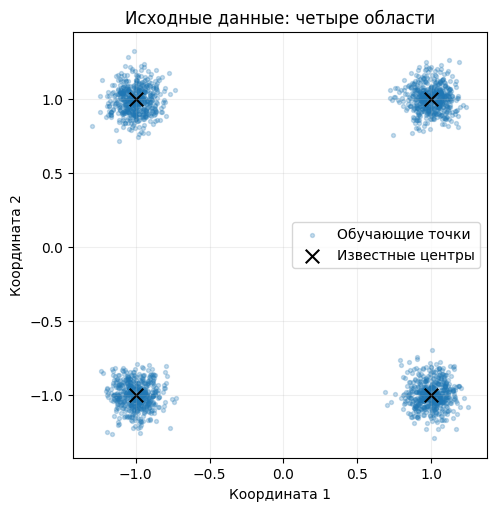

Обучающая выборка: (2048, 2)
Опорная выборка: (1000, 2)


In [2]:
centers = torch.tensor([
    [-1.0, -1.0],
    [-1.0,  1.0],
    [ 1.0, -1.0],
    [ 1.0,  1.0],
], device=device)
data_rng = torch.Generator(device=device).manual_seed(11)
reference_rng = torch.Generator(device=device).manual_seed(13)

real_points = centers.repeat_interleave(512, dim=0)
real_points = real_points + 0.09 * torch.randn(
    2048, 2, generator=data_rng, device=device
)
reference_points = centers.repeat_interleave(250, dim=0)
reference_points = reference_points + 0.09 * torch.randn(
    1000, 2, generator=reference_rng, device=device
)

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.scatter(
    real_points[:, 0].numpy(), real_points[:, 1].numpy(),
    s=8, alpha=0.25, color="tab:blue", label="Обучающие точки"
)
ax.scatter(
    centers[:, 0].numpy(), centers[:, 1].numpy(),
    s=95, marker="x", color="black", label="Известные центры"
)
ax.set(
    title="Исходные данные: четыре области",
    xlabel="Координата 1", ylabel="Координата 2"
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend()
fig.savefig(result_dir / "01_исходные_данные.png", dpi=150)
plt.show()
print("Обучающая выборка:", tuple(real_points.shape))
print("Опорная выборка:", tuple(reference_points.shape))

**Разбор кода и результата**

- `torch.tensor(...)` создаёт тензор из вложенного списка. Внешние квадратные скобки объединяют четыре строки; каждая внутренняя пара — две координаты. Числа с точкой имеют вещественный тип.
- `torch.Generator(...)` создаёт **генератор случайных чисел**, а не нейросеть GAN. Метод `manual_seed(...)` задаёт его начальное состояние и возвращает этот же объект. Разные состояния `11` и `13` дают отдельные последовательности для выборок.
- `repeat_interleave(512, dim=0)` повторяет каждую строку 512 раз. `dim=0` указывает ось строк. Для опорной выборки повторений 250; поэтому размеры выборок составляют 2048 и 1000 точек.
- `torch.randn(2048, 2, ...)` создаёт таблицу случайных чисел со стандартным нормальным распределением. `generator=...` выбирает источник случайности, `device=...` — устройство. Умножение на `0.09` уменьшает разброс, а сложение с центрами смещает точки к нужным областям.
- `fig, ax = plt.subplots(...)` распаковывает два объекта: рисунок и область рисования. `figsize` задаёт размер, `layout="constrained"` размещает подписи. Параметры после `=` в вызове — именованные аргументы.
- `real_points[:, 0]` выбирает все строки и первый столбец; `[:, 1]` — второй. `numpy()` переводит тензор на процессоре в массив NumPy для рисунка.
- `scatter(...)` рисует точки; `s` задаёт размер, `alpha` — прозрачность, `color` — цвет, `marker` — значок, `label` — подпись легенды.
- `set(...)` задаёт заголовок и названия осей. `set_aspect("equal", adjustable="box")` сохраняет одинаковый масштаб единицы по обеим осям. `grid(...)` добавляет сетку, `legend()` — легенду.
- `fig.savefig(...)` сохраняет рисунок, `dpi=150` задаёт разрешение. `plt.show()` показывает его в ячейке.
- `shape` содержит размеры тензора; `tuple(...)` представляет их кортежем. `print(...)` показывает размеры. Две колонки — признаки объекта, а не ответы для D.

### Латентный код

Генератор получает случайный вектор, который называют **латентным кодом**. Его координаты не являются координатами готовой точки и не имеют заранее заданного смысла вроде «номер области». Связь между кодом и результатом формируется в ходе обучения.

В учебной модели длина кода равна двум. Это отдельная настройка: она не обязана совпадать с количеством признаков создаваемого объекта. Сохраним один набор кодов для наблюдения за обучением: тогда изменения рисунка будут вызваны изменением сети, а не заменой входных векторов.

Подготовим неизменный набор из 512 латентных векторов. Выведем первые четыре строки и размеры: каждая строка будет входом для создания одной точки. Отдельный источник случайности не влияет на будущий выбор обучающих пакетов.

In [3]:
latent_size = 2
monitor_rng = torch.Generator(device=device).manual_seed(101)
fixed_noise = torch.randn(
    512, latent_size, generator=monitor_rng, device=device
)
print("Размер набора кодов:", tuple(fixed_noise.shape))
print("Первые четыре кода:")
print(fixed_noise[:4])

Размер набора кодов: (512, 2)
Первые четыре кода:
tensor([[-0.6028, -0.1208],
        [-0.4323,  1.8811],
        [-0.7158,  0.0026],
        [ 0.2056,  0.5626]])


**Разбор кода**

- `latent_size = 2` сохраняет целое число — длину одного входного вектора.
- `torch.Generator(...).manual_seed(101)` создаёт отдельный воспроизводимый источник случайных чисел. Цепочка через точку вызывает метод у только что созданного объекта.
- `torch.randn(512, latent_size, ...)` формирует 512 строк по два значения. Здесь случайные числа являются **входами генератора**, а в предыдущем примере они задавали разброс исходных данных.
- `tuple(fixed_noise.shape)` выводит размеры. `fixed_noise[:4]` — срез: строки от нуля до трёх, правая граница не включается. Отсутствие числа слева от `:` означает начало.
- `print(...)` показывает результаты. Мы будем повторно подавать весь `fixed_noise` в сеть, не изменяя сам тензор.

## 3. Две сети и разные цели обучения

### Выходы генератора и дискриминатора

В G два входных числа преобразуются в два числа — координаты новой точки. В D координаты преобразуются в одно число — **логит** происхождения. Положительный логит означает склонность D считать объект исходным, отрицательный — созданным генератором.

У D не будет выходного слоя Sigmoid: выбранная функция потерь уже объединяет нужное преобразование с вычислением ошибки. Для понятного вывода отдельно преобразуем логит в оценку от 0 до 1. Она относится к происхождению в текущем состязании, а не является универсальной оценкой качества объекта.

Сети содержат только полносвязные слои и LeakyReLU. Dropout и Batch Normalization здесь не нужны. На выходе G нет ограничения диапазона: случайные исходные точки иногда выходят за координаты центров.

Опишем G и D как отдельные классы PyTorch, затем создадим демонстрационную пару. Проверим форму выходов и число обучаемых параметров. Функция создания пары позволит позже начать основное обучение с исходного состояния, независимо от демонстрационных обновлений.

In [4]:
class Generator(nn.Module):
    def __init__(self, latent_size=2, hidden_size=32):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(latent_size, hidden_size),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_size, hidden_size),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_size, 2),
        )

    def forward(self, noise):
        return self.layers(noise)


class Discriminator(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(2, hidden_size),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_size, hidden_size),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_size, 1),
        )

    def forward(self, points):
        return self.layers(points)


def make_models(seed=37, latent_size=2, hidden_size=32):
    torch.manual_seed(seed)
    generator = Generator(latent_size, hidden_size).to(device)
    discriminator = Discriminator(hidden_size).to(device)
    return generator, discriminator


demo_g, demo_d = make_models()
with torch.no_grad():
    demo_points = demo_g(fixed_noise[:4])
    demo_logits = demo_d(demo_points)
print("Выход G:", tuple(demo_points.shape))
print("Выход D:", tuple(demo_logits.shape))
print("Параметров G:", sum(p.numel() for p in demo_g.parameters()))
print("Параметров D:", sum(p.numel() for p in demo_d.parameters()))

Выход G: (4, 2)
Выход D: (4, 1)
Параметров G: 1218
Параметров D: 1185


**Разбор кода и результата**

- `class Generator(nn.Module)` определяет собственный класс с возможностями базового `nn.Module`. Имя `Generator` здесь относится к **нейросети**; запись `torch.Generator` выше относилась к случайным числам.
- `def` определяет функцию или метод. `__init__` выполняется при создании экземпляра; `self` обозначает этот экземпляр. Значения `latent_size=2`, `hidden_size=32` используются по умолчанию, если аргументы не переданы.
- `super().__init__()` вызывает подготовку базового `nn.Module`. `self.layers = ...` сохраняет слои как часть модели, чтобы PyTorch отслеживал их параметры.
- `nn.Sequential(...)` выполняет слои последовательно. `nn.Linear(...)` задаёт входную и выходную ширину полносвязного слоя. `nn.LeakyReLU(0.2)` пропускает отрицательные значения с ослаблением, заданным аргументом `0.2`.
- `forward(...)` описывает прохождение входа через модель. `return` возвращает результат. При вызове `demo_g(...)` PyTorch сам запускает этот метод, сохраняя механизмы `nn.Module`.
- Класс `Discriminator` устроен аналогично, но получает две координаты и выдаёт один логит. В его последнем слое нет Sigmoid.
- `make_models(...)` сначала вызывает `torch.manual_seed(...)`, затем создаёт G и D в фиксированном порядке. `to(device)` размещает параметры на устройстве. Возврат через запятую позволяет распаковать пару в `demo_g, demo_d`.
- `with torch.no_grad():` отключает построение графа градиентов внутри блока. Двоеточие начинает блок; отступы показывают его строки. Здесь мы только проверяем выходы.
- `fixed_noise[:4]` берёт четыре вектора. `shape` и `tuple(...)` показывают: G возвращает четыре строки по две координаты, `demo_d(...)` — четыре строки по одному логиту.
- `parameters()` перебирает обучаемые тензоры; `p.numel()` считает элементы каждого. Выражение `... for p in ...` подаёт количества в `sum(...)`. Получаем **1218 параметров G** и **1185 параметров D**. `print(...)` выводит проверки.

Сравним выход необученного G с опорными точками. Вспомогательная функция будет подбирать границы так, чтобы были видны все объекты обеих выборок. Разные цвета покажут, что случайная инициализация ещё не воспроизводит четыре исходные области.

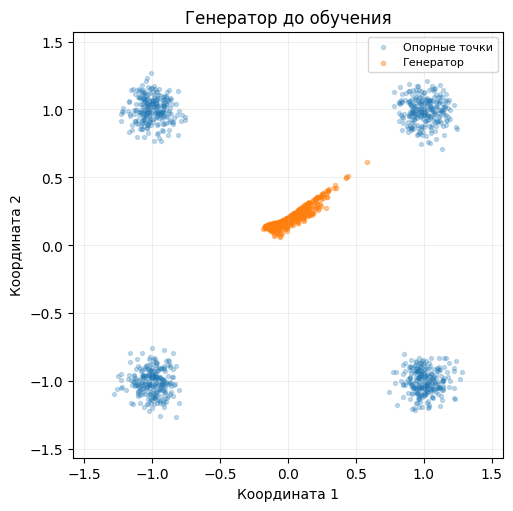

In [5]:
def plot_comparison(ax, reference, generated, title):
    reference_array = reference.detach().cpu().numpy()
    generated_array = generated.detach().cpu().numpy()
    combined = np.concatenate([reference_array, generated_array], axis=0)
    lower = combined.min(axis=0) - 0.3
    upper = combined.max(axis=0) + 0.3
    ax.scatter(
        reference_array[:, 0], reference_array[:, 1],
        s=8, alpha=0.25, label="Опорные точки", color="tab:blue"
    )
    ax.scatter(
        generated_array[:, 0], generated_array[:, 1],
        s=9, alpha=0.4, label="Генератор", color="tab:orange"
    )
    ax.set(
        title=title, xlabel="Координата 1", ylabel="Координата 2",
        xlim=(lower[0], upper[0]), ylim=(lower[1], upper[1])
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)


with torch.no_grad():
    initial_demo_points = demo_g(fixed_noise)
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
plot_comparison(ax, reference_points, initial_demo_points, "Генератор до обучения")
fig.savefig(result_dir / "02_до_обучения.png", dpi=150)
plt.show()

**Разбор кода и результата**

- `def plot_comparison(...)` определяет функцию с четырьмя аргументами: область рисунка, две выборки и заголовок. Она ничего явно не возвращает, а изменяет переданный объект `ax`.
- `detach()` отделяет тензор от графа градиентов; `cpu()` переносит его на процессор, если необходимо; `numpy()` получает массив для Matplotlib. Это действия для отображения, а не шаг обучения.
- `np.concatenate([...], axis=0)` объединяет строки массивов. `min(axis=0)` и `max(axis=0)` находят границы отдельно по каждой координате. Вычитание и прибавление `0.3` дают поля по краям.
- `scatter(...)` рисует выборки; `[:, 0]` и `[:, 1]` выбирают координаты. Малые `s` и `alpha` позволяют видеть плотные скопления точек.
- `set(...)` задаёт подписи и границы. Кортеж `(lower[0], upper[0])` содержит левую и правую границы; квадратные скобки выбирают элементы массива.
- `set_aspect(...)`, `grid(...)`, `legend(...)` настраивают масштаб, сетку и легенду; `fontsize=8` уменьшает текст легенды.
- `with torch.no_grad()` вычисляет точки через `demo_g(...)` без градиентов. `plt.subplots(...)` создаёт рисунок, `plot_comparison(...)` оформляет его, `savefig(...)` сохраняет PNG, `plt.show()` отображает.
- Оранжевые точки пока занимают небольшую область. Наличие двух выходных координат само по себе не заставляет G создавать нужные объекты.

### Три сочетания «выход — целевой ответ»

При обновлении D исходные объекты получают целевой ответ `1`, синтетические — `0`. При обновлении G его синтетические объекты получают **желаемый ответ дискриминатора** `1`. Их происхождение от этого не меняется: меняется цель оптимизации G.

Используем распространённый вариант обучения генератора, который называют *non-saturating*: G обучается увеличивать склонность D принимать его результаты за исходные. Здесь не нужно вручную вычитать оценку или писать отдельную формулу.

Функция `BCEWithLogitsLoss` принимает логиты и целевые значения одинаковой формы. Передавать в неё уже преобразованные через Sigmoid оценки не нужно. Такое сочетание описано в [документации PyTorch](https://docs.pytorch.org/docs/2.11/generated/torch.nn.BCEWithLogitsLoss.html).

Покажем целевые ответы в таблице, затем сравним логиты и оценки необученного дискриминатора. Это проверка смысла входов функции потерь; величины здесь ещё не характеризуют обученную GAN.

In [6]:
criterion = nn.BCEWithLogitsLoss()
roles = pd.DataFrame([
    {"Обновляем": "D", "Вход D": "Исходные точки", "Цель": 1},
    {"Обновляем": "D", "Вход D": "Точки G", "Цель": 0},
    {"Обновляем": "G", "Вход D": "Точки G через D", "Цель": 1},
])
with torch.no_grad():
    logits = demo_d(real_points[:4])
    scores = torch.sigmoid(logits)
    example_loss = criterion(logits, torch.ones_like(logits))
print(roles.to_string(index=False))
print("\nЛогиты D:", logits.flatten().tolist())
print("Оценки после Sigmoid:", scores.flatten().tolist())
print("Ошибка D для четырёх исходных точек:", round(example_loss.item(), 4))

Обновляем          Вход D  Цель
        D  Исходные точки     1
        D         Точки G     0
        G Точки G через D     1



Логиты D: [-0.150008887052536, -0.14792869985103607, -0.14472433924674988, -0.14377325773239136]
Оценки после Sigmoid: [0.46256792545318604, 0.4630851149559021, 0.4638819396495819, 0.46411845088005066]
Ошибка D для четырёх исходных точек: 0.7691


**Разбор кода и результата**

- `nn.BCEWithLogitsLoss()` создаёт объект функции потерь. Его можно вызывать как функцию: `criterion(выход, цель)`.
- `pd.DataFrame([...])` создаёт таблицу из списка словарей. В словаре `{...}` слева от `:` стоит ключ — название столбца, справа — значение. Запятые разделяют поля и записи.
- `with torch.no_grad()` отключает граф. `demo_d(real_points[:4])` обрабатывает четыре исходные точки.
- `torch.sigmoid(logits)` преобразует логиты в числа между нулём и единицей **только для вывода**. Потеря по-прежнему получает `logits`.
- `torch.ones_like(logits)` создаёт единицы с той же формой и типом. Каждой строке выхода соответствует цель `1`.
- `to_string(index=False)` переводит таблицу в текст без дополнительного столбца индексов; `False` означает «ложь». `print(...)` показывает таблицу и значения. Символы `\n` внутри строки начинают новую строку.
- `flatten()` объединяет размеры тензора в одну последовательность; `tolist()` переводит значения в обычный список Python.
- `item()` извлекает одно число из тензора; `round(..., 4)` округляет его. Значения после Sigmoid — текущие ответы D, а не вероятность того, что вся GAN уже обучилась.

## 4. Один цикл обучения: сначала D, затем G

В фазе D генератор служит источником синтетических объектов, а в фазе G дискриминатор служит частью пути, по которому к генератору приходит градиент. Поэтому используем отдельные оптимизаторы и явно управляем связями между сетями.

| Фаза | Меняем параметры | Что происходит со второй сетью |
|---|---|---|
| Обновление D | Только D | Выход G отделяется через `detach()` |
| Обновление G | Только G | Параметры D временно заморожены, но производная по входу D сохраняется |

Разберём фазы на демонстрационной паре. Основное обучение затем начнётся заново, чтобы эти шаги не повлияли на результат.

Создадим два оптимизатора и функции для проверки изменения параметров. Снимки параметров будут независимыми копиями: так можно сравнить состояние сети до и после одного шага.

In [7]:
def parameter_snapshot(model):
    return {
        name: parameter.detach().clone()
        for name, parameter in model.named_parameters()
    }


def parameters_unchanged(model, snapshot):
    return all(
        torch.equal(parameter.detach(), snapshot[name])
        for name, parameter in model.named_parameters()
    )


demo_g_optimizer = torch.optim.Adam(
    demo_g.parameters(), lr=0.001, betas=(0.5, 0.999)
)
demo_d_optimizer = torch.optim.Adam(
    demo_d.parameters(), lr=0.001, betas=(0.5, 0.999)
)
demo_rng = torch.Generator(device=device).manual_seed(5)
print("Число именованных тензоров G:", len(parameter_snapshot(demo_g)))
print("Число именованных тензоров D:", len(parameter_snapshot(demo_d)))
print("Шаг обучения G:", demo_g_optimizer.param_groups[0]["lr"])
print("Шаг обучения D:", demo_d_optimizer.param_groups[0]["lr"])

Число именованных тензоров G: 6
Число именованных тензоров D: 6
Шаг обучения G: 0.001
Шаг обучения D: 0.001


**Разбор кода**

- `def` создаёт функции, `return` возвращает результат. Аргумент `model` позволяет применить одну функцию к G или D.
- `named_parameters()` перебирает пары «имя, тензор». В `for name, parameter in ...` пара распаковывается в две переменные.
- `{name: ... for ...}` — включение словаря: для каждого имени создаётся запись с копией параметра. `detach()` отделяет её от графа, `clone()` выделяет отдельные данные. Без копии снимок мог бы измениться вместе с сетью.
- `torch.equal(...)` проверяет точное равенство тензоров. `snapshot[name]` получает копию по имени. `all(...)` возвращает `True`, только если равны все пары параметров; выражение с `for` передаёт проверки по очереди.
- `torch.optim.Adam(...)` создаёт оптимизатор. `parameters()` передаёт ему параметры одной модели; `lr=0.001` задаёт шаг обучения, `betas=(0.5, 0.999)` — параметры накопления истории обновлений. Это настройки маленького примера, а не универсальный рецепт GAN.
- Оптимизаторы существуют отдельно: вызов одного не изменяет параметры, переданные только другому.
- `torch.Generator(...).manual_seed(5)` создаёт источник случайности для демонстраций. `parameter_snapshot(...)` получает снимок, `len(...)` считает записи словаря.
- `param_groups[0]["lr"]` выбирает первую группу параметров и значение по ключу `"lr"`. `print(...)` показывает настройки и число тензоров, а не число отдельных элементов внутри них.

Выполним один шаг дискриминатора. Он увидит пакет исходных точек и пакет точек G. Отделим выход генератора от графа, затем проверим, что D изменился, а G сохранил параметры и отсутствие градиентов.

In [8]:
g_before_d = parameter_snapshot(demo_g)
d_before_d = parameter_snapshot(demo_d)
demo_d_optimizer.zero_grad(set_to_none=True)

indices = torch.randint(
    len(real_points), (128,), generator=demo_rng, device=device
)
real_batch = real_points[indices]
noise = torch.randn(128, latent_size, generator=demo_rng, device=device)
detached_fake = demo_g(noise).detach()
real_logits = demo_d(real_batch)
fake_logits = demo_d(detached_fake)
d_loss = 0.5 * (
    criterion(real_logits, torch.ones_like(real_logits))
    + criterion(fake_logits, torch.zeros_like(fake_logits))
)
d_loss.backward()
demo_d_optimizer.step()

d_step_checks = {
    "G сохранил параметры": parameters_unchanged(demo_g, g_before_d),
    "D изменил параметры": not parameters_unchanged(demo_d, d_before_d),
    "У G нет градиентов": all(p.grad is None for p in demo_g.parameters()),
}
print("Ошибка D:", round(d_loss.item(), 4))
print(pd.Series(d_step_checks).to_string())

Ошибка D: 0.6957
G сохранил параметры    True
D изменил параметры     True
У G нет градиентов      True


**Разбор кода и результата**

- `parameter_snapshot(...)` делает копии параметров. `zero_grad(set_to_none=True)` очищает накопленные градиенты D, устанавливая их в `None` — отсутствие значения.
- `torch.randint(len(real_points), (128,), ...)` выбирает 128 случайных индексов от нуля до размера выборки, не включая верхнюю границу. Повторения возможны. `(128,)` — кортеж из одного элемента; запятая отличает его от числа в скобках.
- `real_points[indices]` выбирает строки по индексам. `torch.randn(...)` создаёт латентные векторы.
- `demo_g(noise).detach()` даёт точки G без связи с его параметрами. Вызовы `demo_d(...)` всё ещё строят граф дискриминатора.
- `torch.ones_like(...)` задаёт цель `1` для исходных объектов, `torch.zeros_like(...)` — цель `0` для синтетических. `criterion(...)` вычисляет потери; множитель `0.5` усредняет их. Это соглашение масштаба ошибки D в материале.
- `backward()` вычисляет градиенты, `demo_d_optimizer.step()` обновляет параметры D.
- В словаре `d_step_checks` сохранены именованные проверки. `parameters_unchanged(...)` сравнивает сеть со снимком; `not` меняет логическое значение на противоположное.
- `p.grad is None` проверяет отсутствие градиента. `all(... for p in demo_g.parameters())` требует этого для всех параметров G.
- `pd.Series(...)` превращает словарь в подписанный столбец; `to_string()` готовит его к выводу. `item()`, `round(...)`, `print(...)` показывают ошибку и проверки. Все три проверки должны быть `True`: обучался только D.

**Полученный результат.** Все три проверки равны `True`: после одного шага изменился только D, а у G не появились градиенты. Числовая потеря здесь нужна для проверки вычислений, а не для вывода о качестве GAN.

Теперь обновим G. Очистим старые градиенты D и временно запретим вычислять новые градиенты для его параметров. При этом оставим путь от ответа D к точкам G: по нему генератор получает обучающий сигнал.

In [9]:
g_before_g = parameter_snapshot(demo_g)
d_before_g = parameter_snapshot(demo_d)
demo_d_optimizer.zero_grad(set_to_none=True)
for parameter in demo_d.parameters():
    parameter.requires_grad_(False)
demo_g_optimizer.zero_grad(set_to_none=True)

noise = torch.randn(128, latent_size, generator=demo_rng, device=device)
generated_for_g = demo_g(noise)
logits_for_g = demo_d(generated_for_g)
g_loss = criterion(logits_for_g, torch.ones_like(logits_for_g))
g_loss.backward()
g_gradient_size = sum(p.grad.abs().sum().item() for p in demo_g.parameters())
d_has_no_gradients = all(p.grad is None for p in demo_d.parameters())
demo_g_optimizer.step()
for parameter in demo_d.parameters():
    parameter.requires_grad_(True)

g_step_checks = {
    "G изменил параметры": not parameters_unchanged(demo_g, g_before_g),
    "D сохранил параметры": parameters_unchanged(demo_d, d_before_g),
    "К G пришёл ненулевой градиент": g_gradient_size > 0,
    "Новых градиентов D нет": d_has_no_gradients,
}
print("Ошибка G:", round(g_loss.item(), 4))
print(pd.Series(g_step_checks).to_string())

Ошибка G: 0.7422
G изменил параметры              True
D сохранил параметры             True
К G пришёл ненулевой градиент    True
Новых градиентов D нет           True


**Разбор кода и результата**

- `parameter_snapshot(...)` сохраняет состояние сетей. `demo_d_optimizer.zero_grad(set_to_none=True)` удаляет градиенты предыдущего шага, иначе проверка могла бы увидеть старые значения.
- `for parameter in demo_d.parameters():` перебирает параметры D. `requires_grad_(False)` отключает накопление градиентов **для этих параметров**. Подчёркивание в конце имени метода PyTorch указывает на изменение существующего объекта.
- `demo_g_optimizer.zero_grad(...)` очищает градиенты G. `torch.randn(...)` создаёт новый пакет входов.
- Вызовы `demo_g(noise)` и `demo_d(generated_for_g)` образуют цепочку. На выходе G нет `detach()`, а вызовы не находятся в `no_grad()`: граф до параметров G сохраняется.
- `criterion(..., torch.ones_like(...))` задаёт желаемый ответ D `1`. `backward()` проходит через операции D к G, хотя параметры D заморожены.
- `p.grad.abs()` берёт модули градиентов, `sum()` у тензора складывает их, `item()` получает число. Внешний `sum(... for p in ...)` объединяет результаты. Это проверка поступления сигнала, а не новая потеря.
- `all(p.grad is None for p in ...)` проверяет отсутствие новых градиентов D. `step()` вызывается только у оптимизатора G.
- Второй цикл с `requires_grad_(True)` возвращает готовность D к следующему шагу.
- `not`, `> 0` и `parameters_unchanged(...)` формируют результаты проверок. `pd.Series(...).to_string()`, `print(...)`, `round(g_loss.item(), 4)` показывают их. Все четыре результата должны быть `True`.

**Полученный результат.** Все четыре проверки равны `True`. Замороженный D сохранил параметры и не накопил новых градиентов, но через его операции к G пришёл ненулевой сигнал, и G обновился.

### Почему заморозка D не равна разрыву цепочки

Во время обучения G нам не нужно обновлять параметры D, но нужно знать, как ответ D меняется при изменении его входа. Заморозка параметров сохраняет эту возможность. `detach()` после G или блок `no_grad()` вокруг D разорвали бы нужный путь.

Методы `train()` и `eval()` имеют другое назначение: они меняют поведение отдельных слоёв, а не заменяют управление градиентами. В наших сетях нет Dropout и Batch Normalization, поэтому их режим не меняет численный результат.

Чередование обновлений и роль отделения выходов G показаны в [официальном примере PyTorch по DCGAN](https://raw.githubusercontent.com/pytorch/tutorials/main/beginner_source/dcgan_faces_tutorial.py). Мы используем маленькие полносвязные сети и потерю для логитов.

Сравним две цепочки без обновления весов и без намеренного вызова ошибки. У корректной потери останется связь с G, а у потери с отделёнными точками графа уже не будет. Проверка свойства тензора покажет различие напрямую.

In [10]:
for parameter in demo_d.parameters():
    parameter.requires_grad_(False)
probe_points = demo_g(fixed_noise[:4])
correct_logits = demo_d(probe_points)
broken_logits = demo_d(probe_points.detach())
correct_loss = criterion(correct_logits, torch.ones_like(correct_logits))
broken_loss = criterion(broken_logits, torch.ones_like(broken_logits))
print("Корректная потеря связана с графом:", correct_loss.requires_grad)
print("Потеря после detach связана с графом:", broken_loss.requires_grad)
for parameter in demo_d.parameters():
    parameter.requires_grad_(True)

Корректная потеря связана с графом: True
Потеря после detach связана с графом: False


**Разбор кода и результата**

- Цикл `for` с `parameters()` и `requires_grad_(False)` замораживает параметры D. Параметры G по-прежнему допускают вычисление градиентов.
- `demo_g(fixed_noise[:4])` создаёт четыре точки, связанные с G. `demo_d(probe_points)` сохраняет этот путь.
- `probe_points.detach()` создаёт представление без связи с G. Поскольку параметры D тоже заморожены, вычислять градиенты в этой ветке не для чего.
- `criterion(...)` и `torch.ones_like(...)` задают одинаковую цель обеим веткам. Различие находится в графе, а не в выбранном ответе.
- `requires_grad` без подчёркивания и скобок — свойство тензора. `print(...)` показывает `True` для корректной потери и `False` для разорванной цепочки.
- Мы не вызываем `backward()` у второй потери: это привело бы к исключению, а не к обучению. Последний цикл с `requires_grad_(True)` восстанавливает D. Ни один оптимизатор здесь не выполняет шаг.

## 5. Полное обучение маленькой GAN

### Начальное состояние и наблюдение

Создадим новую пару сетей с исходными настройками. Она не наследует демонстрационные обновления. Сохраним состояние генерации до обучения, затем после 100, 500 и 2000 итераций.

В одной итерации выполняются один шаг D и один шаг G. Пакеты исходных точек выбираются случайно с повторениями; здесь итерации не называются эпохами. При каждом обновлении G берётся новый латентный пакет.

Потери записываются в момент вычисления соответствующего шага. Для наблюдения после обоих обновлений вычислим средние ответы D на опорные точки и на результат G для фиксированного шума. Эти вычисления не обновляют параметры.

Подготовим основную пару, оптимизаторы, источник случайности для обучения и пустой журнал. Начальная генерация сохраняется отдельно от параметров: последующие обновления не изменят записанные точки.

In [11]:
generator, discriminator = make_models()
g_optimizer = torch.optim.Adam(
    generator.parameters(), lr=0.001, betas=(0.5, 0.999)
)
d_optimizer = torch.optim.Adam(
    discriminator.parameters(), lr=0.001, betas=(0.5, 0.999)
)
train_rng = torch.Generator(device=device).manual_seed(71)
steps = 2000
batch_size = 128
history_rows = []
with torch.no_grad():
    snapshots = {0: generator(fixed_noise).detach().clone()}
print("Итераций:", steps)
print("Объектов в пакете:", batch_size)
print("Сохранённые этапы:", list(snapshots))

Итераций: 2000
Объектов в пакете: 128
Сохранённые этапы: [0]


**Разбор кода**

- `make_models()` создаёт новую пару G и D через распаковку результата. Значение seed по умолчанию внутри функции — `37`.
- Каждый `torch.optim.Adam(...)` получает свои `parameters()`. `lr` и `betas` совпадают с демонстрационными настройками, но история оптимизаторов начинается заново.
- `torch.Generator(...).manual_seed(71)` задаёт последовательность для выбора обучающих строк и латентных кодов. Она не зависит от `monitor_rng`.
- `steps` и `batch_size` — целые числа. `history_rows = []` создаёт пустой список для записей.
- `with torch.no_grad()` вычисляет исходный результат `generator(fixed_noise)` без графа. `{0: ...}` — словарь, где ключ `0` означает номер итерации.
- `detach().clone()` сохраняет отдельную копию тензора. В данном блоке `detach()` избыточен для градиентов, но явно обозначает назначение снимка как данных.
- `list(snapshots)` получает список ключей словаря. `print(...)` показывает настройки; пока сохранён только этап `0`.

Запустим 2000 итераций. Две фазы повторяют разобранные шаги: отделение G при обучении D и заморозку параметров D при обучении G. Журнал заполняется каждые 20 итераций; наблюдение использует фиксированные входы без дополнительных случайных чисел.

In [12]:
generator.train()
discriminator.train()

for step in range(1, steps + 1):
    # Фаза D: исходные точки против отделённых точек генератора.
    d_optimizer.zero_grad(set_to_none=True)
    indices = torch.randint(
        len(real_points), (batch_size,), generator=train_rng, device=device
    )
    real_batch = real_points[indices]
    noise_for_d = torch.randn(
        batch_size, latent_size, generator=train_rng, device=device
    )
    real_logits = discriminator(real_batch)
    fake_logits = discriminator(generator(noise_for_d).detach())
    d_loss = 0.5 * (
        criterion(real_logits, torch.ones_like(real_logits))
        + criterion(fake_logits, torch.zeros_like(fake_logits))
    )
    d_loss.backward()
    d_optimizer.step()

    # Фаза G: параметры D заморожены, но путь от D к G открыт.
    d_optimizer.zero_grad(set_to_none=True)
    for parameter in discriminator.parameters():
        parameter.requires_grad_(False)
    g_optimizer.zero_grad(set_to_none=True)
    noise_for_g = torch.randn(
        batch_size, latent_size, generator=train_rng, device=device
    )
    logits_for_g = discriminator(generator(noise_for_g))
    g_loss = criterion(logits_for_g, torch.ones_like(logits_for_g))
    g_loss.backward()
    g_optimizer.step()
    for parameter in discriminator.parameters():
        parameter.requires_grad_(True)

    if step in (100, 500, steps):
        with torch.no_grad():
            snapshots[step] = generator(fixed_noise).detach().clone()
    if step == 1 or step % 20 == 0:
        with torch.no_grad():
            real_score = torch.sigmoid(discriminator(reference_points)).mean().item()
            fake_score = torch.sigmoid(discriminator(generator(fixed_noise))).mean().item()
        history_rows.append({
            "step": step,
            "d_loss": d_loss.item(),
            "g_loss": g_loss.item(),
            "d_reference": real_score,
            "d_generated": fake_score,
        })

generator.eval()
discriminator.eval()
history = pd.DataFrame(history_rows)
selected_history = history[history["step"].isin([1, 100, 500, 1000, 2000])]
print(selected_history.round(4).to_string(index=False))
print("Сохранённые этапы:", list(snapshots))

 step  d_loss  g_loss  d_reference  d_generated
    1  0.6953  0.7417       0.4777       0.4765
  100  0.5711  1.0788       0.5053       0.3519
  500  0.5906  0.8398       0.5586       0.4397
 1000  0.6437  0.8219       0.5246       0.4782
 2000  0.6850  0.7276       0.5109       0.4926
Сохранённые этапы: [0, 100, 500, 2000]


**Разбор кода**

- `train()` переводит модели в режим обучения. Здесь нет слоёв с различным поведением в режимах, но порядок показывает назначение этапа.
- `range(1, steps + 1)` выдаёт номера от `1` до `2000`: правая граница не включается. Цикл `for` повторяет блок с отступом. Строки после `#` — комментарии.
- В фазе D `zero_grad(...)` очищает градиенты, `torch.randint(...)` выбирает индексы, `len(...)` задаёт верхнюю границу. `torch.randn(...)` создаёт коды, `detach()` разрывает путь к G. Два вызова `criterion(...)` с `ones_like(...)` и `zeros_like(...)` обучают D различать происхождение. `backward()` считает градиенты, `d_optimizer.step()` меняет D.
- Перед фазой G ещё один `d_optimizer.zero_grad(...)` удаляет использованные градиенты D. Цикл по `parameters()` с `requires_grad_(False)` замораживает его параметры. Вызовы `discriminator(generator(...))` сохраняют градиентный путь к G.
- `g_optimizer.zero_grad(...)`, `criterion(..., torch.ones_like(...))`, `backward()` и `g_optimizer.step()` обновляют G. Затем `requires_grad_(True)` готовит D к следующей итерации.
- `if` выполняет блок при истинном условии. `step in (...)` проверяет принадлежность кортежу. Снимки с ключами `100`, `500`, `2000` получаются в `torch.no_grad()` и копируются через `detach().clone()`.
- `==` сравнивает значения, `%` получает остаток деления, `or` означает «хотя бы одно условие». Поэтому журнал заполняется на шаге 1 и на шагах, кратных 20.
- `torch.sigmoid(...)` преобразует логиты D для наблюдения, `mean()` находит среднее, `item()` получает число Python. На это время граф отключён. Опорные точки не участвуют в `backward()`.
- `append({...})` добавляет словарь в список. `pd.DataFrame(...)` превращает записи в таблицу. `history["step"].isin([...])` создаёт логическую маску нужных строк; внешние `[...]` выбирают их.
- `eval()` включает режим использования моделей; это не отключает градиенты автоматически. `round(4)` у таблицы округляет числа, `to_string(index=False)` оформляет вывод, `list(...)` показывает ключи снимков, `print(...)` выводит результат.

**Полученный результат.** На итерации 2000 потеря D составила около **0,685**, G — **0,728**. После обновлений средние ответы D на опорные точки и на генерацию фиксированных входов составили примерно **0,511** и **0,493**. Эти близкие ответы предстоит сопоставить с самими точками; они не являются доказательством совпадения выборок.

### Как читать журнал

В обычной задаче с фиксированными данными часто ожидают плавного уменьшения ошибки. В GAN обе сети меняются: улучшение D может сделать задачу G труднее, а улучшение G — затруднить работу D. Колебания сами по себе не доказывают неисправность обучения.

Сравнивать потери G и D как соревнование «у кого меньше — тот лучше» нельзя: у них разные цели, а потеря D дополнительно усреднена по двум источникам. Средний ответ D около `0.5` также не доказывает хорошее качество: D может быть слабым, а среднее способно скрыть неоднородность объектов. Нужны сами образцы и проверка разнообразия.

Построим рядом журнал потерь и средние оценки D. Слева показаны значения потерь при обновлениях, справа — ответы на фиксируемые для наблюдения наборы после обновлений.

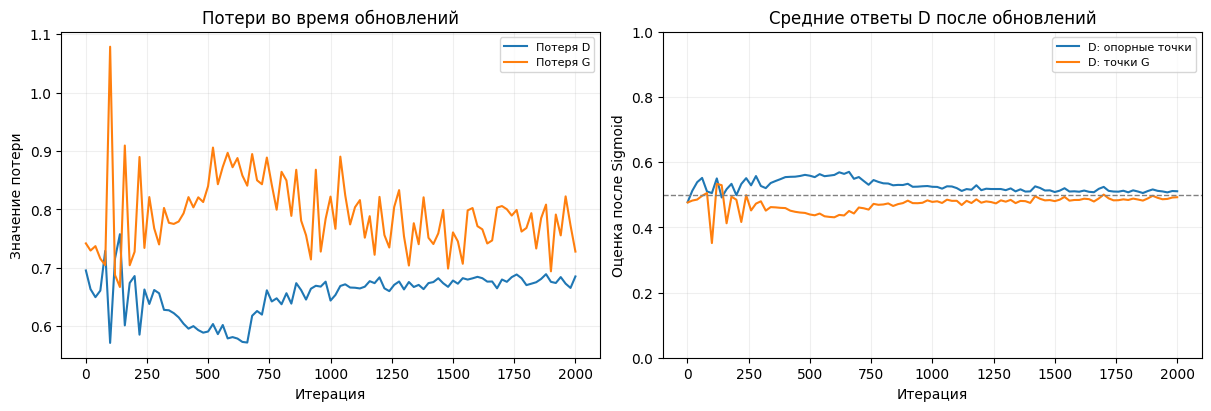

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(history["step"], history["d_loss"], label="Потеря D")
axes[0].plot(history["step"], history["g_loss"], label="Потеря G")
axes[0].set(
    title="Потери во время обновлений",
    xlabel="Итерация", ylabel="Значение потери"
)
axes[1].plot(
    history["step"], history["d_reference"], label="D: опорные точки"
)
axes[1].plot(
    history["step"], history["d_generated"], label="D: точки G"
)
axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
axes[1].set(
    title="Средние ответы D после обновлений",
    xlabel="Итерация", ylabel="Оценка после Sigmoid", ylim=(0, 1)
)
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.savefig(result_dir / "03_журнал_обучения.png", dpi=150)
plt.show()

**Разбор кода и результата**

- `plt.subplots(1, 2, ...)` создаёт одну строку из двух областей; `axes[0]` и `axes[1]` выбирают их. `layout="constrained"` распределяет место под подписи.
- `plot(...)` соединяет наблюдения линиями. `history["step"]` выбирает столбец итераций; остальные ключи выбирают показатели. `label` задаёт подпись линии.
- `set(...)` оформляет заголовки и оси; `ylim=(0, 1)` фиксирует диапазон оценок справа.
- `axhline(0.5, ...)` проводит горизонтальный ориентир. `linestyle="--"` делает линию пунктирной, `linewidth=1` задаёт толщину. Это ориентир ответа D, а не линия «обучение завершено».
- Цикл `for ax in axes` применяет `grid(...)` и `legend(...)` к обеим областям.
- `fig.savefig(...)` сохраняет рисунок, `plt.show()` показывает его. Слева G и D вычисляют потери в разные фазы; справа оценивается состояние после обеих фаз. Кривые не заменяют просмотр результатов генерации.

Посмотрим, как одни и те же 512 латентных кодов преобразуются до обучения и после выбранных итераций. Каждая панель включает все свои точки; масштабы между панелями могут различаться. Это позволяет увидеть ранние неудачные результаты без обрезания координат.

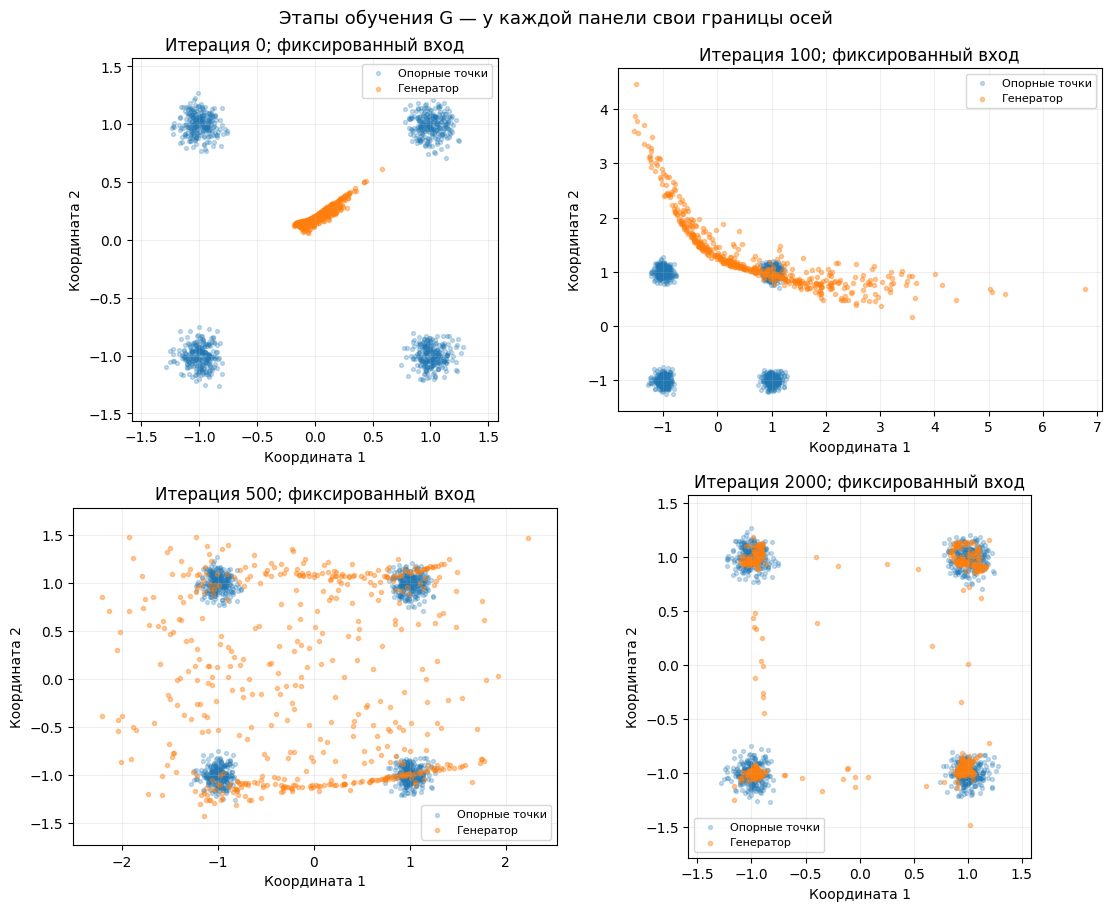

 Итерация  Минимальная координата  Максимальная координата
        0                  -0.184                    0.614
      100                  -1.540                    6.785
      500                  -2.213                    2.234
     2000                  -1.481                    1.200


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout="constrained")
for ax, step in zip(axes.flat, (0, 100, 500, 2000)):
    plot_comparison(
        ax, reference_points, snapshots[step],
        f"Итерация {step}; фиксированный вход"
    )
fig.suptitle("Этапы обучения G — у каждой панели свои границы осей", fontsize=13)
fig.savefig(result_dir / "04_этапы_генерации.png", dpi=150)
plt.show()
snapshot_ranges = pd.DataFrame([
    {
        "Итерация": step,
        "Минимальная координата": points.min().item(),
        "Максимальная координата": points.max().item(),
    }
    for step, points in snapshots.items()
])
print(snapshot_ranges.round(3).to_string(index=False))

**Разбор кода и результата**

- `plt.subplots(2, 2, ...)` создаёт четыре области. `axes.flat` перебирает их по строкам как одну последовательность.
- `zip(...)` объединяет область и номер итерации в пары. Цикл `for ax, step in ...` распаковывает их.
- `snapshots[step]` выбирает сохранённые точки. `plot_comparison(...)` вычисляет границы по обеим выборкам конкретной панели, сохраняя одинаковый масштаб двух осей внутри неё.
- `f"Итерация {step}..."` — форматируемая строка: выражение в фигурных скобках заменяется значением переменной.
- `suptitle(...)` задаёт общий заголовок, `savefig(...)` сохраняет рисунок, `plt.show()` отображает.
- `snapshots.items()` перебирает пары «ключ, значение». Списковое включение `[{...} for ...]` создаёт запись для каждого этапа.
- `points.min()` и `points.max()` находят крайние значения среди всех координат; `item()` извлекает числа. `pd.DataFrame(...)`, `round(3)`, `to_string(index=False)` и `print(...)` показывают таблицу диапазонов.
- Ранний G может выдавать точки далеко от исходных областей. Сравнивать размер скоплений на разных панелях без учёта осей нельзя. Для итогового сравнения далее используем общую область рисунка.

**Что видно на сохранённых этапах.** На итерации 100 часть координат достигает примерно **6,78**, хотя центры исходных областей находятся около −1 и 1. К итерации 500 появляются все четыре скопления, но между ними ещё много точек. К итерации 2000 основная масса сосредоточена около центров; отдельные промежуточные объекты остаются. Неудачный ранний этап сохранён как часть реального хода обучения.

## 6. Качество примеров и разнообразие

### Новые входы после обучения

Зафиксированный шум полезен для наблюдения, но не показывает всю работу генератора. Создадим новый набор латентных кодов, который не использовался ни в обновлениях, ни в снимках обучения.

После обучения G сам преобразует код в объект. Дискриминатор для такого использования не требуется. Повторение одного кода при неизменной детерминированной сети даёт тот же объект; новый код позволяет получить другой объект без дополнительного обучения.

Сгенерируем 1000 точек с новым источником случайности и проверим повторяемость фиксированных входов. Обе выборки на рисунке получат общие границы осей: их расположение можно сравнивать напрямую.

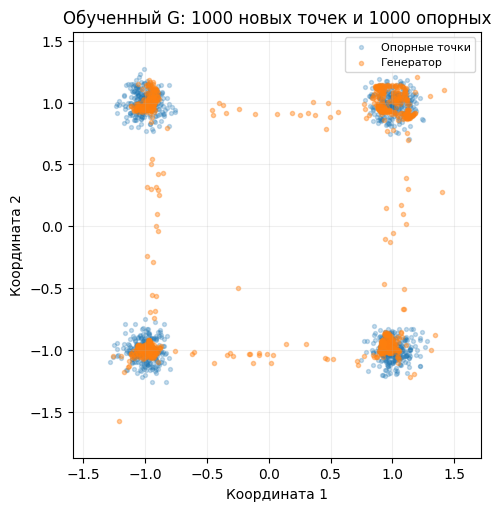

Одинаковый вход даёт одинаковый результат: True
Число новых объектов: 1000


In [15]:
evaluation_rng = torch.Generator(device=device).manual_seed(303)
fresh_noise = torch.randn(
    1000, latent_size, generator=evaluation_rng, device=device
)
with torch.no_grad():
    generated_points = generator(fresh_noise)
    fixed_result_a = generator(fixed_noise)
    fixed_result_b = generator(fixed_noise)
same_input_same_output = torch.allclose(fixed_result_a, fixed_result_b)

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
plot_comparison(
    ax, reference_points, generated_points,
    "Обученный G: 1000 новых точек и 1000 опорных"
)
fig.savefig(result_dir / "05_новые_точки.png", dpi=150)
plt.show()
print("Одинаковый вход даёт одинаковый результат:", same_input_same_output)
print("Число новых объектов:", len(generated_points))

**Разбор кода и результата**

- `torch.Generator(...).manual_seed(303)` задаёт отдельную последовательность для итогового просмотра. `torch.randn(...)` создаёт 1000 новых латентных векторов.
- В `with torch.no_grad()` три вызова `generator(...)` выполняют только генерацию. Дискриминатор не участвует; ни `backward()`, ни шаг оптимизатора не выполняются.
- `torch.allclose(...)` проверяет близость тензоров с небольшим числовым допуском. Оба раза используется один `fixed_noise`, поэтому ожидается `True`. В этой модели нет случайных слоёв при генерации.
- `plt.subplots(...)` создаёт рисунок. `plot_comparison(...)` показывает опорные и новые точки в одних координатах; `savefig(...)` и `plt.show()` сохраняют и выводят изображение.
- `len(generated_points)` считает строки, `print(...)` показывает проверку и размер выборки.
- Смотрим не только на наличие четырёх скоплений, но и на точки между ними, разброс и неравномерность заполнения. Итог G может оставаться несовершенным после выбранного числа итераций.

**Что видно на новых входах.** Все четыре области представлены, однако в отдельных скоплениях оранжевые точки расположены теснее исходных, а часть результатов соединяет области. Значит, наличие четырёх групп ещё не означает полного воспроизведения разброса исходных данных. Проверка одинаковых входов вернула `True`.

### Потеря разнообразия: mode collapse

**Mode collapse** — ситуация, когда генератор выдаёт слишком ограниченный набор объектов и пропускает существенные варианты исходных данных. Например, он может сосредоточиться только на одной из четырёх областей. Отдельная точка при этом может выглядеть правдоподобно.

Чтобы разделить правдоподобие отдельных объектов и разнообразие, добавим **ручную контрольную выборку из одинаковых точек**. Это специально созданный контрпример, а не сохранённый сбой нашей GAN.

Поскольку источник данных известен, введём понятную диагностику: считаем точку близкой к области, если расстояние до её центра меньше `0.35`. Это выбранный порог для нашего масштаба, а не универсальная метрика GAN. Посчитаем представленные области, доли по областям и долю точек вне них. В реальных изображениях обычно нет таких известных центров, поэтому напрямую переносить этот способ оценки нельзя.

Проблемы потери разнообразия и нестабильного обучения разобраны в [материале Google о трудностях обучения GAN](https://developers.google.com/machine-learning/gan/problems).

Сравним три одинаковые по размеру выборки: опорные точки, результат G и ручной пример потери разнообразия. Помимо среднего ответа D выведем геометрические показатели. Их совместное чтение покажет ограничения одного лишь дискриминатора.

In [16]:
region_radius = 0.35
collapsed_points = centers[0].expand_as(generated_points).clone()

def describe_samples(name, points):
    distances = torch.cdist(points, centers)
    nearest_distance, nearest_region = distances.min(dim=1)
    close = nearest_distance < region_radius
    counts = torch.bincount(nearest_region[close], minlength=4)
    outside = (~close).sum().item()
    with torch.no_grad():
        mean_score = torch.sigmoid(discriminator(points)).mean().item()
    summary = {
        "Выборка": name,
        "Близко к областям, %": close.float().mean().item() * 100,
        "Представлено областей": (counts > 0).sum().item(),
        "Средняя оценка D": mean_score,
        "Вне областей": outside,
    }
    return summary, counts.tolist() + [outside]


sample_sets = {
    "Опорная": reference_points,
    "GAN": generated_points,
    "Ручной коллапс": collapsed_points,
}
summaries = []
region_counts = {}
for name, points in sample_sets.items():
    summary, counts = describe_samples(name, points)
    summaries.append(summary)
    region_counts[name] = counts
quality_table = pd.DataFrame(summaries)
print(quality_table.round(3).to_string(index=False))
print("\nКоличество точек по областям 1–4 и вне областей:")
print(pd.DataFrame(region_counts, index=["1", "2", "3", "4", "Вне"]).to_string())

       Выборка  Близко к областям, %  Представлено областей  Средняя оценка D  Вне областей
       Опорная                 100.0                      4             0.511             0
           GAN                  93.2                      4             0.490            68
Ручной коллапс                 100.0                      1             0.507             0



Количество точек по областям 1–4 и вне областей:
     Опорная  GAN  Ручной коллапс
1        250  264            1000
2        250  221               0
3        250  187               0
4        250  260               0
Вне        0   68               0


**Разбор кода и результата**

- `centers[0]` берёт первый центр. `expand_as(generated_points)` повторяет его представление до формы выборки G, `clone()` создаёт отдельный тензор. Все строки одинаковы по построению.
- `def describe_samples(...)` задаёт функцию диагностики. `torch.cdist(points, centers)` считает расстояния от каждой точки до четырёх центров.
- `min(dim=1)` возвращает два тензора: наименьшее расстояние в каждой строке и индекс центра. Распаковка сохраняет их отдельно.
- `< region_radius` создаёт логическую маску. `nearest_region[close]` выбирает номера областей близких точек. `torch.bincount(..., minlength=4)` считает объекты по четырём индексам, включая нулевые количества.
- `~close` инвертирует маску. `sum().item()` считает точки за пределами порога. В `torch.no_grad()` вызов `discriminator(points)` с `torch.sigmoid(...)`, `mean()` и `item()` даёт средний ответ D без обновлений.
- `close.float()` переводит `False` и `True` в `0` и `1` для получения доли через `mean()`. Умножение на `100` выражает её в процентах. `(counts > 0).sum()` считает представленные области.
- `return summary, counts.tolist() + [outside]` возвращает словарь и список количеств. Здесь `+` объединяет списки, добавляя пятый показатель.
- `sample_sets` — словарь трёх выборок. `items()` даёт пары имени и данных. В цикле `describe_samples(...)` возвращает две части; `append(...)` добавляет описание, `region_counts[name] = counts` сохраняет количества.
- `pd.DataFrame(...)` создаёт таблицы; `index=[...]` задаёт подписи строк второй. `round(3)`, `to_string(...)` и `print(...)` оформляют вывод.
- Ручная выборка близка к одному центру, но представляет одну область. Её ответ D может оказаться около `0.5`, как и у разнообразных данных. Это не подтверждает полноту генерации.

**Разбор чисел.** Из 1000 результатов G **932 точки (93,2%)** попали в заданные окрестности, **68** остались снаружи. По областям получено **264, 221, 187 и 260** точек: разнообразие есть, доли не полностью совпадают с опорными 250 в каждой области. У ручного коллапса все 1000 точек находятся в первой области. При этом средний ответ D для него примерно **0,507**, для опорных точек — **0,511**, а для G — **0,490**. Почти одинаковые средние ответы скрывают очень разное разнообразие.

Переведём количества в доли и сопоставим пять категорий: четыре области и точки за их пределами. На одном рисунке будут видны потеря областей, неравномерность и объекты между скоплениями.

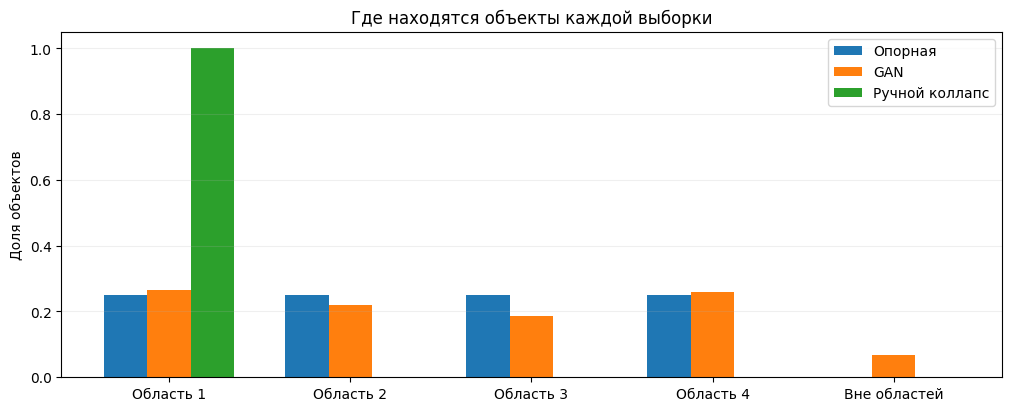

In [17]:
labels = ["Область 1", "Область 2", "Область 3", "Область 4", "Вне областей"]
x = np.arange(len(labels))
width = 0.24
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for offset, (name, counts) in enumerate(region_counts.items()):
    shares = np.array(counts) / len(sample_sets[name])
    ax.bar(x + (offset - 1) * width, shares, width=width, label=name)
ax.set_xticks(x, labels)
ax.set(
    title="Где находятся объекты каждой выборки",
    ylabel="Доля объектов", ylim=(0, 1.05)
)
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.savefig(result_dir / "06_разнообразие.png", dpi=150)
plt.show()

**Разбор кода и результата**

- `labels = [...]` создаёт список подписей. `len(labels)` считает их, `np.arange(...)` создаёт позиции от нуля до четырёх.
- `width = 0.24` задаёт ширину столбика. `plt.subplots(...)` создаёт рисунок.
- `region_counts.items()` перебирает имена и списки количеств. `enumerate(...)` добавляет номер, начиная с нуля. В `for offset, (name, counts) in ...` распаковываются номер и вложенная пара.
- `np.array(counts)` переводит список в массив. Деление на `len(sample_sets[name])` получает доли по всей выборке, включая точки вне областей.
- `bar(...)` рисует столбики; смещение `x + (offset - 1) * width` ставит три серии рядом. `label` подписывает серию.
- `set_xticks(x, labels)` связывает позиции с названиями. `set(...)` оформляет заголовок и диапазон долей. `grid(axis="y", ...)` добавляет горизонтальные линии, `legend()` показывает легенду.
- `savefig(...)` сохраняет рисунок, `plt.show()` выводит.
- Представить четыре области недостаточно: одна может содержать почти все объекты. По исходной конструкции ожидаются близкие доли около четверти в каждой области, а пятая категория должна оставаться небольшой.

### Почему обучение бывает неустойчивым

Если D слишком легко отличает текущие подделки, G может получать мало полезной информации о том, как улучшить их. Если D слишком слаб, его ответы тоже плохо направляют G. Поэтому сильная классификация D сама по себе не является целью всей GAN.

При потере разнообразия разработчики сопоставляют новые образцы на нескольких этапах, проверяют чередование обновлений и градиентный путь, затем при необходимости меняют шаги обучения или соотношение обновлений сетей. Универсального числа шагов D на один шаг G нет: оно зависит от данных и моделей. Изменение этих настроек не гарантирует устранения коллапса, а простое продолжение обучения может закрепить неудачное состояние.

В нашем примере механика обновлений проверена отдельно, обе сети делают по одному шагу за итерацию. Оставшиеся промежуточные точки и различия в разбросе — наблюдаемые ограничения выбранной маленькой модели и конкретного запуска. Их не скрывают увеличением числа итераций до удобного результата.

### Что именно выучил дискриминатор

D обучался отличать исходные точки от результатов текущего G. Он не обязан давать геометрически понятную карту качества на всей плоскости. В областях, где почти не было обучающих объектов, его ответы могут быть неинформативны.

Покажем ответы D на сетке. Цвет отразит склонность считать точку исходной, а не плотность исходных данных. Сравнение карты с расположением областей помогает понять ограничения D.

Вычислим ответы D на сетке, охватывающей обе выборки. На карту нанесём точки G и известные центры. Подпись цветовой шкалы укажет, что изображено.

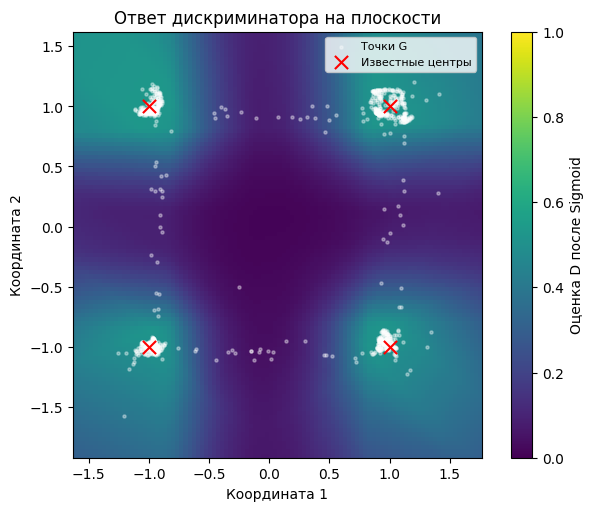

In [18]:
combined_points = torch.cat([reference_points, generated_points], dim=0)
lower = combined_points.min(dim=0).values - 0.35
upper = combined_points.max(dim=0).values + 0.35
grid_x = torch.linspace(lower[0].item(), upper[0].item(), 100, device=device)
grid_y = torch.linspace(lower[1].item(), upper[1].item(), 100, device=device)
mesh_y, mesh_x = torch.meshgrid(grid_y, grid_x, indexing="ij")
grid_points = torch.stack([mesh_x.flatten(), mesh_y.flatten()], dim=1)
with torch.no_grad():
    score_map = torch.sigmoid(discriminator(grid_points)).reshape(100, 100)

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
picture = ax.imshow(
    score_map.cpu().numpy(), origin="lower",
    extent=(lower[0].item(), upper[0].item(), lower[1].item(), upper[1].item()),
    vmin=0, vmax=1, cmap="viridis", aspect="equal"
)
ax.scatter(
    generated_points[:, 0].numpy(), generated_points[:, 1].numpy(),
    s=5, alpha=0.35, color="white", label="Точки G"
)
ax.scatter(
    centers[:, 0].numpy(), centers[:, 1].numpy(),
    marker="x", s=90, color="red", label="Известные центры"
)
ax.set(
    title="Ответ дискриминатора на плоскости",
    xlabel="Координата 1", ylabel="Координата 2"
)
ax.legend(fontsize=8)
fig.colorbar(picture, ax=ax, label="Оценка D после Sigmoid")
fig.savefig(result_dir / "07_карта_дискриминатора.png", dpi=150)
plt.show()

**Разбор кода и результата**

- `torch.cat([...], dim=0)` объединяет строки выборок. `min(dim=0).values` и `max(dim=0).values` выбирают крайние координаты; свойство `values` получает числовую часть результата. Отступ оставляет поля.
- `torch.linspace(начало, конец, 100, ...)` создаёт 100 равномерных позиций по оси. `item()` переводит границы в числа Python.
- `torch.meshgrid(grid_y, grid_x, indexing="ij")` строит координаты ячеек. Порядок `y`, затем `x` соответствует строкам и столбцам изображения.
- `flatten()` разворачивает сетки. `torch.stack([...], dim=1)` собирает пары координат в таблицу из 10 000 строк.
- В `torch.no_grad()` вызов `discriminator(grid_points)` обрабатывает сетку. `torch.sigmoid(...)` получает оценки; `reshape(100, 100)` возвращает их к размеру изображения.
- `plt.subplots(...)` создаёт рисунок. `imshow(...)` показывает массив после `cpu().numpy()`. `origin="lower"` помещает нижнюю строку снизу, `extent` задаёт границы, `vmin=0`, `vmax=1` фиксируют цветовую шкалу, `cmap` выбирает палитру, `aspect="equal"` сохраняет масштаб.
- `scatter(...)` добавляет результаты G и центры; срезы `[:, 0]`, `[:, 1]` выделяют координаты. `set(...)` оформляет оси, `legend(...)` подписывает значки.
- `fig.colorbar(...)` добавляет шкалу, связанную с `picture`; компоновка выделяет ей место. `savefig(...)` сохраняет рисунок, `plt.show()` выводит.
- Цвета за пределами известных областей нельзя трактовать как достоверную вероятность существования исходной точки. Мы наблюдаем поведение классификатора происхождения.

Проверим, совпадают ли новые объекты с конкретными обучающими точками. Найдём ближайшую обучающую точку для каждого результата G. Это ограниченная проверка почти точных копий, которая сама по себе не доказывает отсутствие запоминания.

In [19]:
nearest_training_distance = torch.cdist(
    generated_points, real_points, compute_mode="donot_use_mm_for_euclid_dist"
).min(dim=1).values
copy_tolerance = 0.000001
near_copy_count = (nearest_training_distance < copy_tolerance).sum().item()
novelty_report = pd.Series({
    "Новых точек": len(generated_points),
    "Совпадений в пределах допуска": near_copy_count,
    "Минимальное расстояние": nearest_training_distance.min().item(),
    "Медианное расстояние": nearest_training_distance.median().item(),
    "Максимальное расстояние": nearest_training_distance.max().item(),
})
print(novelty_report.to_string())
print("Допуск для совпадения:", copy_tolerance)

Новых точек                      1000.000000
Совпадений в пределах допуска       0.000000
Минимальное расстояние              0.000277
Медианное расстояние                0.006592
Максимальное расстояние             0.757558
Допуск для совпадения: 1e-06


**Разбор кода и результата**

- `torch.cdist(generated_points, real_points)` получает расстояния от 1000 результатов G до 2048 обучающих объектов. `min(dim=1).values` оставляет ближайшее расстояние для каждого результата.
- `< copy_tolerance` создаёт маску расстояний меньше допуска. `sum().item()` считает такие случаи.
- `len(...)` получает количество строк. `min()`, `median()`, `max()` описывают ближайшие расстояния; `median()` показывает центральное значение упорядоченного набора. `item()` извлекает числа.
- Словарь внутри `pd.Series(...)` связывает подписи и значения. `to_string()` и `print(...)` выводят отчёт и допуск.
- `compute_mode="donot_use_mm_for_euclid_dist"` выбирает прямой способ вычисления расстояний. Он помогает избежать потери точности для близких точек при вычислении через матричные операции. Это всё ещё диагностика с допуском, а не доказательство побитового равенства.
- Даже без почти точных копий сеть может воспроизводить локальные особенности обучающей выборки. Здесь мы не заявляем проверку приватности или отсутствие запоминания.

**Полученный результат.** Совпадений в пределах допуска не обнаружено. Минимальное ближайшее расстояние составляет примерно **0,000277**, медианное — **0,00659**. Это подтверждает отсутствие почти точных копий в данной проверке, но не заменяет оценку структуры и разнообразия сгенерированных объектов.

## 7. Сохранение генератора и его использование

Сохраним G для генерации и небольшие файлы с ходом обучения и диагностикой. При использовании G нужны описание архитектуры, её настройки и обученные параметры.

D и состояния оптимизаторов для создания объектов не требуются. Здесь сохраняется комплект для **генерации**, а не полный снимок для продолжения обучения с того же места.

Запишем параметры генератора, настройки сети, таблицы и поясняющие сведения. Файлы останутся в папке результатов рядом с рисунками. При повторном запуске материал обновит свои результаты под теми же именами.

In [20]:
checkpoint_path = result_dir / "генератор_точек.pt"
torch.save({
    "model_state": generator.state_dict(),
    "latent_size": latent_size,
    "hidden_size": 32,
}, checkpoint_path)
history.to_csv(result_dir / "журнал_обучения.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(
    generated_points.numpy(), columns=["coordinate_1", "coordinate_2"]
).to_csv(result_dir / "новые_точки.csv", index=False, encoding="utf-8-sig")
quality_table.to_csv(
    result_dir / "диагностика_выборок.csv", index=False, encoding="utf-8-sig"
)
metadata = {
    "тема": "Генеративно-состязательные сети: четыре области на плоскости",
    "тип": "безусловная GAN, полносвязные G и D",
    "назначение_сохранения": "генерация, без состояния для продолжения обучения",
    "итераций": steps,
    "объектов_в_пакете": batch_size,
    "обучающих_точек": len(real_points),
    "опорных_точек": len(reference_points),
    "центры": centers.tolist(),
    "разброс_исходных_координат": 0.09,
    "порог_близости_к_областям": region_radius,
    "случайные_состояния": {
        "сети": 37, "данные": 11, "опорная_выборка": 13,
        "обучение": 71, "наблюдение": 101, "итоговые_точки": 303,
    },
    "оптимизаторы": {"название": "Adam", "lr": 0.001, "betas": [0.5, 0.999]},
    "потери": "BCEWithLogitsLoss; D — среднее потерь исходных и синтетических",
    "диагностика": quality_table.to_dict(orient="records"),
    "проверки_шага_D": d_step_checks,
    "проверки_шага_G": g_step_checks,
    "ручной_коллапс": "контроль из одинаковых точек, не сбой обученной модели",
    "загрузки_из_интернета": False,
}
metadata_path = result_dir / "описание_примера.json"
metadata_path.write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Генератор:", checkpoint_path.name)
print("Размер файла генератора, байт:", checkpoint_path.stat().st_size)
print("Описание:", metadata_path.name)

Генератор: генератор_точек.pt
Размер файла генератора, байт: 7701
Описание: описание_примера.json


**Разбор кода**

- Оператор `/` добавляет имя к `result_dir`. `torch.save({...}, checkpoint_path)` сохраняет словарь в файл.
- `state_dict()` возвращает именованные параметры модели. Вместе с ними сохраняются `latent_size` и `hidden_size` для создания такого же G.
- `to_csv(...)` записывает таблицу. `index=False` исключает служебные индексы строк; `encoding="utf-8-sig"` облегчает открытие кириллицы в табличных программах.
- `pd.DataFrame(generated_points.numpy(), columns=[...])` создаёт таблицу с двумя именами столбцов. Мы сохраняем результаты, а не вычислительный граф.
- `metadata` — словарь со строками, числами, вложенными словарями и списками. `centers.tolist()` делает центры списком; `len(...)` записывает размеры выборок.
- `quality_table.to_dict(orient="records")` превращает строки в список словарей для JSON. `False` сохраняет факт отсутствия интернет-загрузок.
- `json.dumps(...)` преобразует структуру в текст JSON; `ensure_ascii=False` оставляет читаемую кириллицу, `indent=2` задаёт отступы.
- `write_text(..., encoding="utf-8")` записывает текст. `name` получает имя файла; `stat().st_size` — его размер. `print(...)` показывает созданные файлы.

Загрузим сохранённый G в новый объект и проверим восстановление на фиксированных входах. Затем создадим несколько точек без обращения к D. Так можно использовать обученный генератор в отдельной программе с доступным классом архитектуры.

In [21]:
saved = torch.load(checkpoint_path, map_location=device, weights_only=True)
restored_generator = Generator(
    latent_size=saved["latent_size"], hidden_size=saved["hidden_size"]
).to(device)
restored_generator.load_state_dict(saved["model_state"])
restored_generator.eval()
inference_rng = torch.Generator(device=device).manual_seed(404)
with torch.no_grad():
    restored_fixed = restored_generator(fixed_noise)
    new_codes = torch.randn(
        5, saved["latent_size"], generator=inference_rng, device=device
    )
    restored_examples = restored_generator(new_codes)
restore_matches = torch.allclose(restored_fixed, fixed_result_a)
print("Восстановленный G повторяет результат:", restore_matches)
print(pd.DataFrame(
    restored_examples.numpy(), columns=["Координата 1", "Координата 2"]
).round(3).to_string(index=False))

Восстановленный G повторяет результат: True
 Координата 1  Координата 2
       -0.974        -0.997
       -0.934         0.969
        0.927        -0.923
       -0.945         1.101
        0.877         1.114


**Разбор кода и результата**

- `torch.load(...)` читает созданный нами файл. `map_location=device` размещает тензоры на процессоре. `weights_only=True` использует ограниченный режим для параметров и простых структур; здесь читается собственный файл.
- `saved["latent_size"]`, `saved["hidden_size"]` и `saved["model_state"]` получают значения по ключам.
- `Generator(...)` создаёт экземпляр уже определённого класса; `to(device)` размещает его на устройстве. `load_state_dict(...)` подставляет параметры. Словарь весов требует соответствующей архитектуры.
- `eval()` включает режим использования. `torch.Generator(...).manual_seed(404)` готовит случайные коды для отдельного показа.
- В `torch.no_grad()` вызовы `restored_generator(...)` обрабатывают фиксированные входы и пять новых кодов от `torch.randn(...)`. D не вызывается.
- `torch.allclose(...)` сравнивает восстановленный результат с результатом исходного G. Ожидается `True`: сохранение и загрузка не должны менять генерацию.
- `numpy()` получает массив; `pd.DataFrame(..., columns=[...])` подписывает столбцы, `round(3)` округляет, `to_string(index=False)` убирает индекс. `print(...)` выводит проверку и пять примеров.

**Полученный результат.** Проверка восстановления вернула `True`. Пять дополнительных точек созданы загруженным G без дискриминатора и без обновления параметров.

## 8. Как эта схема связана с генерацией изображений

В маленьком примере мы изучили механизм состязательного обучения, а не обучили модель изображений. При переходе к изображениям сохраняются роли G и D и чередование обновлений, но меняются представление данных, архитектуры и требования к вычислениям.

| Вариант | Что меняется относительно нашего примера | Что сохраняется |
|---|---|---|
| Полносвязная безусловная GAN из материала | Вход G — только случайный код, выход — две координаты | Две сети с разными целями и поочерёдными обновлениями |
| DCGAN | Используются свёрточные архитектуры; G преобразует код в массив пикселей | Состязательное обучение G и D |
| Условная GAN, cGAN | G и D получают условие, например класс изображения | G создаёт объект, D оценивает его с учётом условия |

DCGAN и cGAN описывают разные стороны решения: первая относится к архитектуре, вторая — к наличию условия. Свёрточная GAN также может быть условной. В нашей сети выбор одного из четырёх кластеров **не задаётся пользователем**: G получает только случайный код.

Архитектуры рассмотрены в [работе о DCGAN](https://arxiv.org/abs/1511.06434), использование условия — в [работе о conditional GAN](https://arxiv.org/abs/1411.1784). Для реалистичных изображений этот учебный код нужно существенно расширять; увеличение числа итераций у генератора точек не превращает его в генератор фотографий.

### Что показал выполненный пример

- На фазе D параметры G не изменялись; на фазе G параметры D оставались прежними, но обучающий сигнал проходил через D.
- Необученный G и ранние этапы не воспроизводили исходную структуру. Итог сравнивался на новых латентных кодах.
- Качество отдельного объекта, разнообразие и средний ответ D — разные характеристики. Ручная выборка из одинаковых точек показала это различие.
- Для создания новых объектов после обучения достаточно сохранённого G, его архитектуры и латентных кодов.

Диффузионные модели относятся к следующей теме и здесь не разбираются.